# Лабораторная работа № 2. Классификация и нейронные сети
## 1. Введение

Цель работы — сравнить методы классификации scikit-learn и полносвязную сеть TensorFlow на задаче определения тяжести ДТП, проверить чувствительность результатов к гиперпараметрам и освоить мониторинг обучения в TensorBoard.

Для воспроизведения из папки ноутбука установите зависимости командой `python -m pip install -r requirements.txt` и выполните все ячейки. Исходные CSV лежат в папке `data`. Журналы TensorBoard для выполненных экспериментов находятся в `tensorboard_logs`.

## 2. Выбор и подготовка данных

Источник — предоставленные для варианта таблицы Car Crash. Происхождение и способ сбора наблюдений в приложенных материалах не указаны. Каждая строка описывает ДТП, а `Severity` содержит один из трёх исходов: `Minor Injury` (лёгкая травма), `Severe Injury` (тяжёлая травма) и `Fatal` (смертельный исход). Признаки описывают столкновение, автомобиль, водителя и условия движения. Работа оценивает классификацию уже произошедших ДТП.

In [1]:
from pathlib import Path
from datetime import datetime
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "Severity"
CLASSES = ["Minor Injury", "Severe Injury", "Fatal"]
class_ids = np.arange(len(CLASSES))
data_dir = Path("data")
train, external, template = [
    pd.read_csv(data_dir / name, keep_default_na=False, na_values=[""])
    for name in ("car_crash_train.csv", "car_crash_test.csv", "sample_submission.csv")
]

X = train.drop(columns=TARGET)
y = train[TARGET].map({name: i for i, name in enumerate(CLASSES)})
numeric = X.select_dtypes(include="number").columns.tolist()
categorical = X.columns.difference(numeric, sort=False).tolist()

audit = pd.DataFrame({
    "Строки": [len(train), len(external), len(template)],
    "Столбцы": [train.shape[1], external.shape[1], template.shape[1]],
    "Пустые ячейки": [train.isna().sum().sum(), external.isna().sum().sum(),
                     template.isna().sum().sum()],
    "Дубли строк": [train.duplicated().sum(), external.duplicated().sum(),
                   template.duplicated().sum()],
}, index=["train", "test", "sample_submission"])
display(audit)
display(pd.DataFrame({
    "Тип": ["Числовой" if name in numeric else "Категориальный" for name in X],
    "Различных значений": X.nunique(),
}))
overlap = train.merge(external, on=list(train.columns)).shape[0]
assert overlap == 0 and y.notna().all()

,Строки,Столбцы,Пустые ячейки,Дубли строк
train,4000,19,0,0
test,1000,19,0,0
sample_submission,5000,2,0,0


,Тип,Различных значений
Crash Speed (km/h),Числовой,180
Impact Angle (degrees),Числовой,180
Airbag Deployed,Категориальный,2
Seatbelt Used,Категориальный,2
Weather Conditions,Категориальный,4
Road Conditions,Категориальный,4
Crash Type,Категориальный,4
Vehicle Type,Категориальный,4
Vehicle Age (years),Числовой,20
Brake Condition,Категориальный,2


В `train` 4000 строк и 7 числовых плюс 11 категориальных признаков. В `test` 1000 размеченных строк и столько же признаков. Пропусков, полных дублей в этих таблицах и совпадающих строк между ними не обнаружено. Строковое значение `None` в `Distraction Level` означает отсутствие отвлечения. При чтении CSV оно сохранено как категория, поскольку пропуском считается пустое поле.

В шаблоне отправки 5000 строк, столбцы `ID` и `Predicted_Severity`. Этот файл используется только для установления его формата. В таблицах признаков отсутствует ключ для сопоставления с UUID шаблона.

## 3. Разбиение выборки и предобработка

,Обучение 80%,Контроль 20%,Подбор NN: обучение,Подбор NN: валидация,Внешний тест
Minor Injury,2205,551,1764,441,710
Severe Injury,830,208,664,166,249
Fatal,165,41,132,33,41


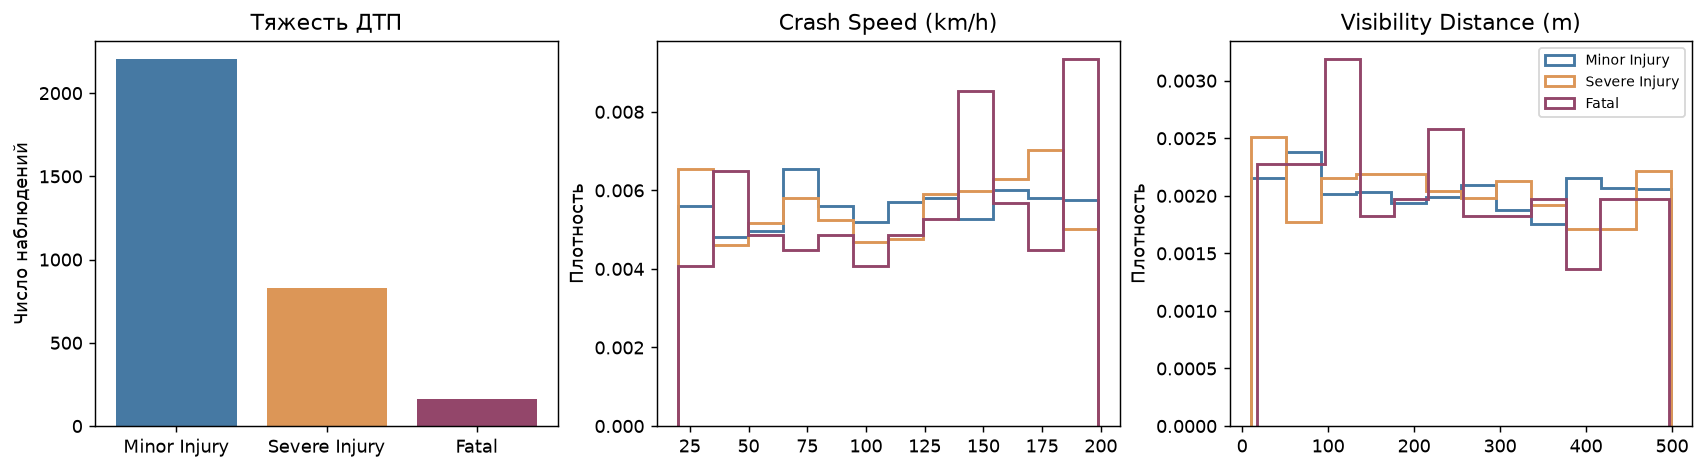

In [2]:
X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=SEED
)
external_y = external[TARGET].map(dict(zip(CLASSES, class_ids)))
external_X = external[X.columns]
splits = {"Обучение 80%": y_train, "Контроль 20%": y_hold, "Подбор NN: обучение": y_fit,
          "Подбор NN: валидация": y_val, "Внешний тест": external_y}
counts = pd.DataFrame({
    name: series.value_counts().reindex(class_ids, fill_value=0).to_numpy()
    for name, series in splits.items()
}, index=CLASSES)
display(counts)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
colors = ["#4679a3", "#dc9657", "#93466a"]
axes[0].bar(CLASSES, counts["Обучение 80%"], color=colors)
axes[0].set(title="Тяжесть ДТП", ylabel="Число наблюдений")
for ax, name in zip(axes[1:], ["Crash Speed (km/h)", "Visibility Distance (m)"]):
    for i, label in enumerate(CLASSES):
        ax.hist(X_train.loc[y_train == i, name], bins=12, density=True,
                histtype="step", linewidth=1.6, color=colors[i], label=label)
    ax.set(title=name, ylabel="Плотность")
axes[2].legend(fontsize=8)
plt.show()


def preprocessing(discretize=False):
    if discretize:
        numeric_transformer = KBinsDiscretizer(
            n_bins=5, encode="onehot-dense", strategy="uniform"
        )
    else:
        numeric_transformer = StandardScaler()
    return ColumnTransformer([
        ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("transform", numeric_transformer)]), numeric),
        ("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore",
                                                   sparse_output=False))]), categorical),
    ])

`train_test_split` со стратификацией и seed 42 разделил исходный `train` на 3200 обучающих и 800 контрольных строк. У нейросети внутри обучения ещё одно разбиение на 2560 строк для подбора и 640 для валидации. В обучающих 80% доля лёгких травм составляет 68,9%, а доля смертельных исходов — 5,2%. Поэтому одной Accuracy для сравнения мало. Гистограммы скорости и видимости сильно перекрываются. Они показывают распределения этих двух признаков по классам по отдельности.

Числовые признаки стандартизируются, категории кодируются one-hot. Заполнение медианой и модой предусмотрено внутри конвейера на случай пропусков. Для MultinomialNB, ComplementNB и BernoulliNB числовые значения переводятся в бинарные индикаторы пяти интервалов. Это даёт неотрицательные входы для первых двух алгоритмов и бинарные для третьего. Преобразования обучаются только на той части данных, на которой обучается модель.

## 4. Методы классификации

| Метод | Принцип |
|---|---|
| Наивный Байес | Сочетает априорные вероятности классов и условные вероятности признаков при предположении условной независимости. GaussianNB моделирует признаки нормальными распределениями, MultinomialNB использует неотрицательные индикаторы как счётчики, ComplementNB оценивает веса по наблюдениям из остальных классов, BernoulliNB моделирует наличие или отсутствие индикатора. |
| Decision Tree | Рекурсивно делит данные по порогам признаков, чтобы сделать дочерние узлы однороднее. |
| LDA | Строит линейные границы, используя оценки средних классов и общую ковариационную матрицу. |
| SVM | Ищет границы с максимальным зазором. Линейное и RBF-ядра позволяют проверить разные формы границы. |
| kNN | Назначает класс по голосам ближайших объектов в пространстве преобразованных признаков. |

## 5. Настройка гиперпараметров

Критерий выбора — средний **макро-F1** на четырёх одинаковых стратифицированных разбиениях обучающих данных. Для каждой модели сравниваются значения из указанной в коде сетки. Дополнительно используется baseline, который всегда предсказывает самый частый класс.

,Комбинаций,Лучший CV macro-F1,SD между блоками,Параметры
GaussianNB,4,0.3235,0.0099,{'var_smoothing': 1e-09}
MultinomialNB,8,0.3139,0.0106,"{'alpha': 10, 'fit_prior': False}"
ComplementNB,8,0.3367,0.0066,"{'alpha': 0.1, 'norm': True}"
BernoulliNB,8,0.3176,0.0086,"{'alpha': 10, 'fit_prior': False}"
Decision Tree,12,0.3388,0.0084,"{'class_weight': None, 'max_depth': None, 'min..."
LDA,8,0.2894,0.0274,"{'priors': None, 'shrinkage': None}"
SVM,12,0.3334,0.0122,"{'C': 10, 'class_weight': 'balanced', 'kernel'..."
kNN,16,0.3243,0.0112,"{'n_neighbors': 5, 'p': 2, 'weights': 'distance'}"


CV F1
Модель        Параметр         Значение                                                  
BernoulliNB   alpha            0.01                                                0.2832
                               0.1                                                 0.2832
                               1.0                                                 0.2833
                               10.0                                                0.3176
              fit_prior        False                                               0.3176
                               True                                                0.2834
ComplementNB  alpha            0.01                                                0.3366
                               0.1                                                 0.3367
                               1.0                                                 0.3314
                               10.0                                                0.3324
              norm             False                                               0.3324
                               True                                                0.3367
Decision Tree class_weight     balanced                                            0.3168
                               nan                                                 0.3388
              max_depth        3                                                   0.2748
                               7                                                   0.3044
                               None                                                0.3388
              min_samples_leaf 25                                                  0.3097
                               5                                                   0.3388
GaussianNB    var_smoothing    0.01                                                0.3182
                               0.1                                                 0.2741
                               1.0                                                 0.2720
                               1e-09                                               0.3235
LDA           priors           None                                                0.2894
                               [0.3333333333333333, 0.3333333333333333, 0.3333...  0.2752
              shrinkage        0.3                                                 0.2720
                               0.8                                                 0.2725
                               None                                                0.2894
                               auto                                                0.2752
MultinomialNB alpha            0.01                                                0.2779
                               0.1                                                 0.2783
                               1.0                                                 0.2820
                               10.0                                                0.3139
              fit_prior        False                                               0.3139
                               True                                                0.2743
SVM           C                0.1                                                 0.2732
                               1.0                                                 0.3267
                               10.0                                                0.3334
              class_weight     balanced                                            0.3334
                               nan                                                 0.3305
              kernel           linear                                              0.2759
                               rbf                                                 0.3334
kNN           n_neighbors      15                                                  0.2926
                               35 

min     max  Разница
Модель        Параметр                                 
Decision Tree max_depth         0.2748  0.3388   0.0640
SVM           C                 0.2732  0.3334   0.0603
              kernel            0.2759  0.3334   0.0576
kNN           n_neighbors       0.2720  0.3243   0.0523
GaussianNB    var_smoothing     0.2720  0.3235   0.0515
MultinomialNB fit_prior         0.2743  0.3139   0.0396
              alpha             0.2779  0.3139   0.0360
BernoulliNB   alpha             0.2832  0.3176   0.0344
              fit_prior         0.2834  0.3176   0.0342
Decision Tree min_samples_leaf  0.3097  0.3388   0.0291
              class_weight      0.3168  0.3388   0.0220
LDA           shrinkage         0.2720  0.2894   0.0174
kNN           p                 0.3100  0.3243   0.0143
LDA           priors            0.2752  0.2894   0.0142
kNN           weights           0.3106  0.3243   0.0137
ComplementNB  alpha             0.3314  0.3367   0.0053
              norm              0.3324  0.3367   0.0043
SVM           class_weight      0.3305  0.3334   0.0029

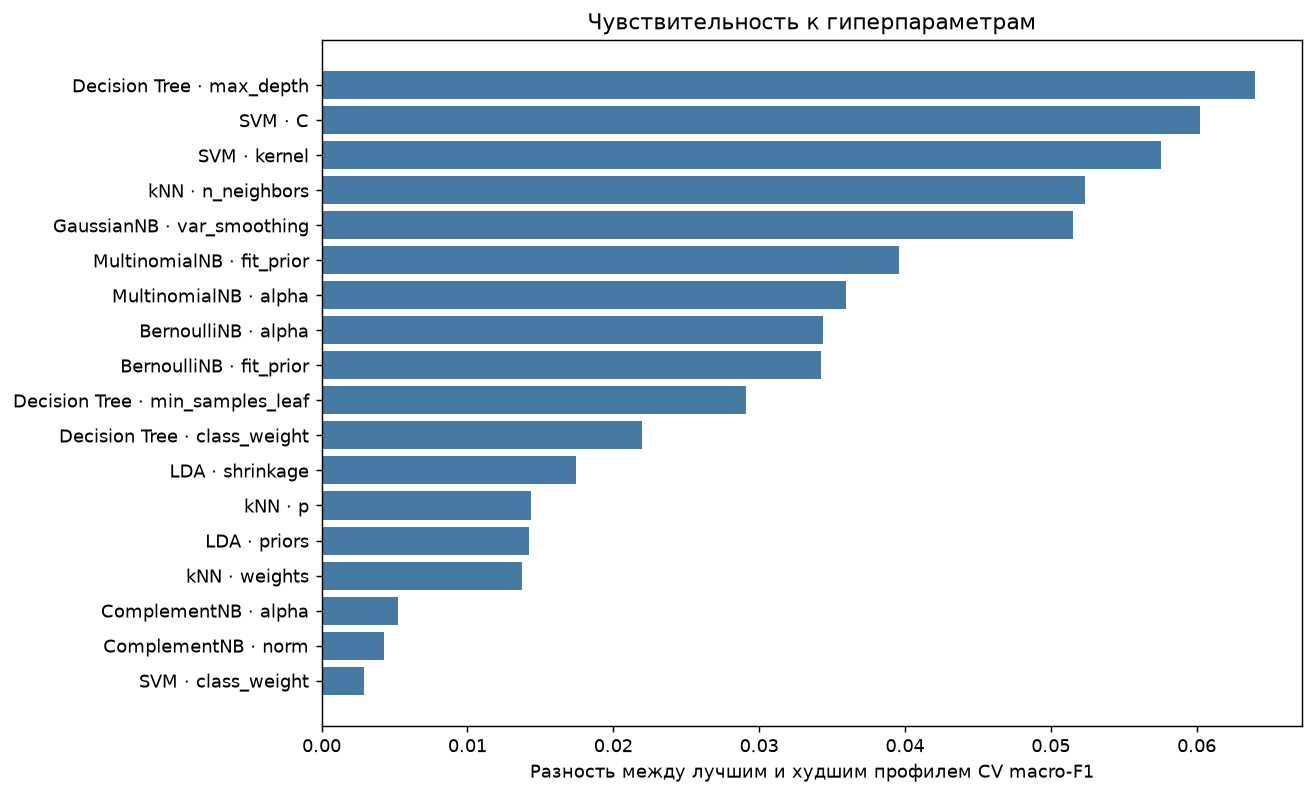

In [3]:
settings = {
    "GaussianNB": (GaussianNB(), {"var_smoothing": [1e-9, 1e-2, 0.1, 1.0]}, False),
    "MultinomialNB": (MultinomialNB(), {"alpha": [0.01, 0.1, 1, 10],
                                       "fit_prior": [True, False]}, True),
    "ComplementNB": (ComplementNB(), {"alpha": [0.01, 0.1, 1, 10],
                                     "norm": [False, True]}, True),
    "BernoulliNB": (BernoulliNB(binarize=None), {"alpha": [0.01, 0.1, 1, 10],
                                              "fit_prior": [True, False]}, True),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {
        "max_depth": [3, 7, None], "min_samples_leaf": [5, 25],
        "class_weight": [None, "balanced"]}, False),
    "LDA": (LinearDiscriminantAnalysis(solver="lsqr"), {
        "shrinkage": [None, "auto", 0.3, 0.8], "priors": [None, [1/3]*3]}, False),
    "SVM": (SVC(cache_size=200), {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"],
                                 "class_weight": [None, "balanced"]}, False),
    "kNN": (KNeighborsClassifier(), {"n_neighbors": [5, 15, 35, 75],
                                    "weights": ["uniform", "distance"],
                                    "p": [1, 2]}, False),
}
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
searches, summaries, parameter_profiles = {}, {}, []
for name, (model, params, discrete) in settings.items():
    pipeline = Pipeline([("preprocess", preprocessing(discrete)), ("model", model)])
    grid = {f"model__{key}": vals for key, vals in params.items()}
    search = GridSearchCV(pipeline, grid, cv=cv, scoring="f1_macro", error_score="raise")
    search.fit(X_train, y_train)
    searches[name] = search
    candidates = pd.DataFrame(search.cv_results_)
    summaries[name] = {"Комбинаций": len(candidates), "Лучший CV macro-F1": search.best_score_,
                       "SD между блоками": candidates.loc[search.best_index_, "std_test_score"],
                       "Параметры": str({k.split("__")[1]: v for k, v in search.best_params_.items()})}
    for parameter in params:
        scores = candidates.assign(value=candidates[f"param_model__{parameter}"].map(str))
        profile = scores.groupby("value", sort=False)["mean_test_score"].max()
        for value, score in profile.items():
            parameter_profiles.append((name, parameter, value, score))

cv_table = pd.DataFrame.from_dict(summaries, orient="index")
profiles = pd.DataFrame(parameter_profiles, columns=["Модель", "Параметр", "Значение", "CV F1"])
effects = profiles.groupby(["Модель", "Параметр"])["CV F1"].agg(["min", "max"])
effects["Разница"] = effects["max"] - effects["min"]
display(cv_table.round(4))
display(profiles.pivot_table(index=["Модель", "Параметр", "Значение"],
                             values="CV F1", aggfunc="first").round(4))
display(effects.sort_values("Разница", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
spread = effects.sort_values("Разница")
ax.barh([f"{model} · {param}" for model, param in spread.index], spread["Разница"],
        color="#4679a3")
ax.set(xlabel="Разность между лучшим и худшим профилем CV macro-F1",
       title="Чувствительность к гиперпараметрам")
plt.show()

Профили показывают лучший средний CV macro-F1 при каждом фиксированном значении параметра, когда прочие параметры выбираются из той же сетки. Разница между максимумом и минимумом профиля измеряет чувствительность в пределах выбранных значений. Она зависит также от возможных взаимодействий параметров. Разброс между блоками показывает, насколько значения менялись при переразбиении данных.

Среди классических моделей по CV лидирует **Decision Tree** (макро-F1 **0,339**). Наибольший размах профиля наблюдается у **Decision Tree** для `max_depth` (**0,064**). По каждой модели видны значения, при которых получился лучший результат. В частности, влияние сглаживания NB и числа соседей kNN можно сравнить непосредственно по строкам `alpha` / `var_smoothing` и `n_neighbors`.

## 6. Нейронная сеть TensorFlow

Вход — стандартизированные числовые признаки и one-hot категории. Базовая архитектура состоит из двух скрытых полносвязных слоёв на 64 и 32 нейрона с ReLU. Выходной слой из трёх нейронов и softmax возвращает вероятности классов. Используются Adam с шагом 0,001 и разреженная категориальная кросс-энтропия (целевые метки заданы целыми числами). Каждый эксперимент меняет один параметр относительно базового варианта. Отдельно проверяются веса классов, обратно пропорциональные их частотам на обучающей части.

In [4]:
import tensorflow as tf

tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()

base = {"layers": (64, 32), "activation": "relu", "epochs": 20,
        "batch": 64, "weighted": False}
variants = {
    "base": {},
    "epochs_10": {"epochs": 10},
    "epochs_40": {"epochs": 40},
    "batch_32": {"batch": 32},
    "batch_128": {"batch": 128},
    "one_layer": {"layers": (64,)},
    "three_layers": {"layers": (64, 32, 16)},
    "narrow": {"layers": (32, 16)},
    "tanh": {"activation": "tanh"},
    "weighted": {"weighted": True},
}
configs = {name: base | changes for name, changes in variants.items()}
log_root = Path("tensorboard_logs") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
nn_transform = preprocessing()
nn_fit = nn_transform.fit_transform(X_fit).astype("float32")
nn_val = nn_transform.transform(X_val).astype("float32")


def train_dataset(vectors, labels, config, training=False):
    labels = np.asarray(labels, dtype=np.int32)
    if training and config["weighted"]:
        weights = len(labels) / (len(CLASSES) * np.bincount(labels, minlength=len(CLASSES)))
        dataset = tf.data.Dataset.from_tensor_slices((vectors, labels, weights[labels].astype("float32")))
    else:
        dataset = tf.data.Dataset.from_tensor_slices((vectors, labels))
    if training:
        dataset = dataset.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    return dataset.batch(config["batch"]).with_options(options)


def fit_network(vectors, labels, config, log_dir, validation=None):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    network = tf.keras.Sequential([
        tf.keras.Input(shape=(vectors.shape[1],)),
        *[tf.keras.layers.Dense(width, activation=config["activation"])
          for width in config["layers"]],
        tf.keras.layers.Dense(len(CLASSES), activation="softmax"),
    ])
    network.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    validation_data = None if validation is None else train_dataset(*validation, config)
    history = network.fit(
        train_dataset(vectors, labels, config, training=True),
        validation_data=validation_data, epochs=config["epochs"], verbose=0,
        callbacks=[tf.keras.callbacks.TensorBoard(log_dir=str(log_dir), update_freq="epoch")],
    )
    return network, pd.DataFrame(history.history)


histories, nn_results = {}, {}
for name, config in configs.items():
    network, history = fit_network(nn_fit, y_fit, config, log_root / name, (nn_val, y_val))
    probability = network(nn_val, training=False).numpy()
    histories[name] = history
    nn_results[name] = {
        **config, "val macro-F1": f1_score(y_val, probability.argmax(axis=1),
                                         average="macro", zero_division=0),
        "val accuracy": history["val_accuracy"].iloc[-1],
        "val loss": history["val_loss"].iloc[-1],
        "min val loss": history["val_loss"].min(),
    }
nn_table = pd.DataFrame.from_dict(nn_results, orient="index").sort_values(
    "val macro-F1", ascending=False, kind="stable"
)
nn_best = nn_table.index[0]
nn_range = nn_table["val macro-F1"].max() - nn_table["val macro-F1"].min()
display(nn_table.round(4))
display((nn_table["val macro-F1"] - nn_table.loc["base", "val macro-F1"]).round(4)
        .rename("Δ macro-F1 к base").to_frame())

,layers,activation,epochs,batch,weighted,val macro-F1,val accuracy,val loss,min val loss
epochs_40,"(64, 32)",relu,40,64,False,0.3315,0.6266,0.9858,0.7587
batch_32,"(64, 32)",relu,20,32,False,0.3279,0.6281,0.8744,0.7595
weighted,"(64, 32)",relu,20,64,True,0.3227,0.4234,0.9890,0.9651
three_layers,"(64, 32, 16)",relu,20,64,False,0.3187,0.6375,0.8947,0.7580
base,"(64, 32)",relu,20,64,False,0.3046,0.6344,0.8041,0.7587
one_layer,"(64,)",relu,20,64,False,0.2876,0.6797,0.7843,0.7654
batch_128,"(64, 32)",relu,20,128,False,0.2743,0.6828,0.7701,0.7589
narrow,"(32, 16)",relu,20,64,False,0.2739,0.6812,0.7802,0.7652
tanh,"(64, 32)",tanh,20,64,False,0.2727,0.6766,0.7804,0.7628
epochs_10,"(64, 32)",relu,10,64,False,0.2720,0.6891,0.7665,0.7587


,Δ macro-F1 к base
epochs_40,0.0270
batch_32,0.0233
weighted,0.0181
three_layers,0.0142
base,0.0000
one_layer,-0.0169
batch_128,-0.0303
narrow,-0.0307
tanh,-0.0319
epochs_10,-0.0326


Параметры сравниваются по макро-F1 на одной и той же валидации после последней эпохи каждого запуска. Лидирует **epochs_40** с макро-F1 **0,332**. У базовой сети макро-F1 **0,305**, размах по десяти конфигурациям **0,060**. Взвешивание даёт изменение макро-F1 +0.018. Вторая таблица показывает эффект изменения каждого параметра относительно базы на этом разбиении. Один seed позволяет повторить эксперимент, но не оценивает разброс результатов между случайными инициализациями.

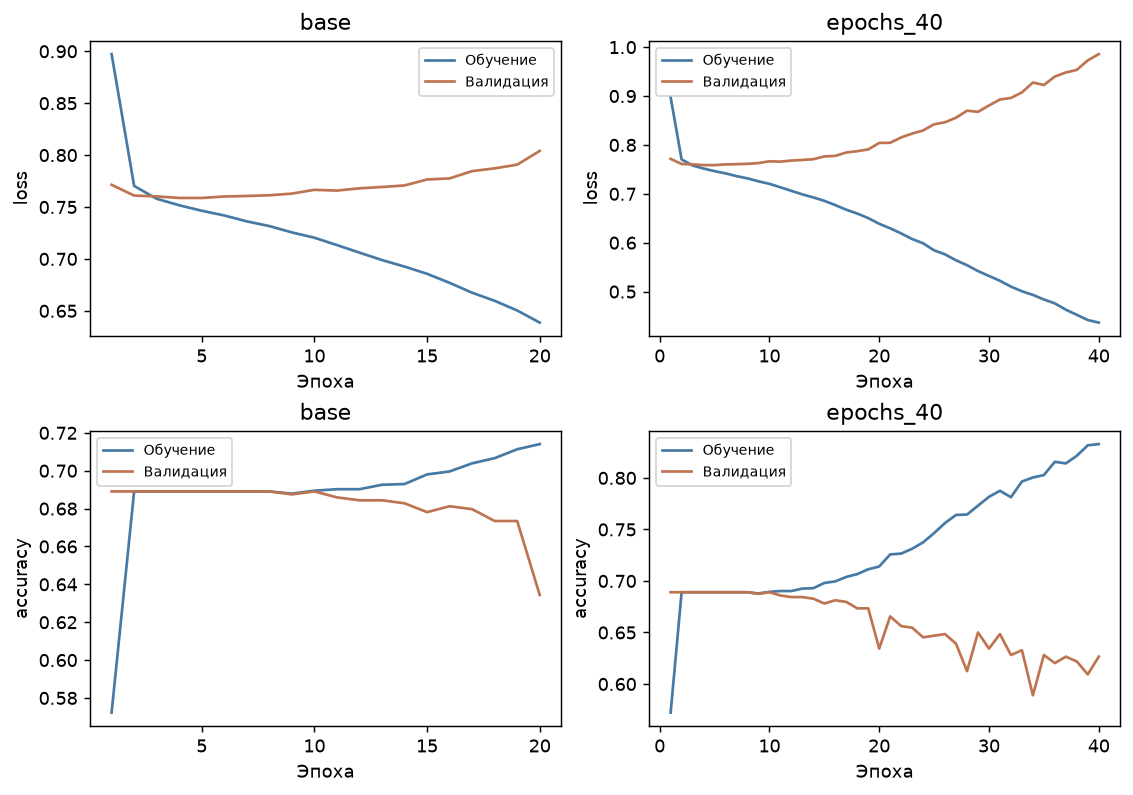

In [5]:
to_show = list(dict.fromkeys(["base", nn_best, "epochs_40"]))
fig, axes = plt.subplots(2, len(to_show), squeeze=False, figsize=(4.3*len(to_show), 6),
                         layout="constrained")
for j, name in enumerate(to_show):
    history = histories[name]
    epoch = np.arange(1, len(history)+1)
    for i, metric in enumerate(["loss", "accuracy"]):
        ax = axes[i, j]
        ax.plot(epoch, history[metric], label="Обучение", color="#4679a3")
        ax.plot(epoch, history[f"val_{metric}"], label="Валидация", color="#bd7450")
        ax.set(xlabel="Эпоха", ylabel=metric, title=name)
        ax.legend(fontsize=8)
plt.show()

Синие линии показывают обучение, оранжевые — валидацию. Для варианта с 40 эпохами минимум валидационной потери достигается на эпохе **5**. К последней эпохе потеря на обучении составляет **0,437**, на валидации — **0,986**. Ухудшение валидационной потери после раннего минимума при продолжении обучения указывает на переобучение. Для взвешенного запуска обучающая loss включает веса классов, а валидационная вычисляется без весов, поэтому их абсолютные уровни следует сравнивать с учётом этой разницы.

Чтобы открыть TensorBoard, запустите из папки ноутбука `tensorboard --logdir tensorboard_logs` и перейдите по адресу `http://localhost:6006`. Во вкладке **Time Series** или **Scalars** выберите запуски **base**, **epochs_40** или другие. Подкаталоги `train` и `validation` содержат ряды `epoch_loss` и `epoch_accuracy`. Если команда `tensorboard` недоступна в Windows, выполните `python -m tensorboard.main --logdir tensorboard_logs` той же версией Python, куда установлены зависимости.

## 7. Сравнительный анализ

Accuracy — доля всех верных ответов. Precision, Recall и F1 сначала вычисляются для каждого класса по схеме «класс против остальных», затем усредняются с равным весом классов (macro). Если класс вовсе не предсказан, его Precision принимается равной нулю. ROC строится по вероятности класса либо по оценке функции решения SVM. Макро-AUC — среднее площадей под тремя отдельными ROC-кривыми. Значение около 0,5 соответствует ранжированию, близкому к случайному.

Классические модели после настройки уже переобучены на всех 3200 обучающих наблюдениях. Выбранная сеть также обучается заново на этих 3200 строках с фиксированными параметрами и числом эпох. Контрольная и внешняя выборки применяются после подбора.

In [6]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
nn_final_transform = clone(nn_transform)
nn_final_vectors = nn_final_transform.fit_transform(X_train).astype("float32")
nn_final, _ = fit_network(nn_final_vectors, y_train, configs[nn_best], log_root / "final_refit")


def predict_all(frame):
    predictions = {"Частый класс": (baseline.predict(frame), baseline.predict_proba(frame))}
    for name, search in searches.items():
        if name == "SVM":
            scores = search.decision_function(frame)
        else:
            scores = search.predict_proba(frame)
        assert np.array_equal(search.classes_, class_ids)
        predictions[name] = (search.predict(frame), scores)
    array = nn_final_transform.transform(frame).astype("float32")
    probability = nn_final(array, training=False).numpy()
    predictions["TensorFlow"] = (probability.argmax(axis=1), probability)
    return predictions


def classification_report(truth, predictions):
    records, curves = {}, {}
    for name, (labels, scores) in predictions.items():
        per_class = [roc_curve(truth == i, scores[:, i])[:2] for i in class_ids]
        areas = [auc(fpr, tpr) for fpr, tpr in per_class]
        curves[name] = per_class
        records[name] = {
            "Accuracy": accuracy_score(truth, labels),
            "Precision": precision_score(truth, labels, average="macro", zero_division=0),
            "Recall": recall_score(truth, labels, average="macro", zero_division=0),
            "F1": f1_score(truth, labels, average="macro", zero_division=0),
            "ROC-AUC": np.mean(areas),
        }
    return pd.DataFrame.from_dict(records, orient="index"), curves


hold_predictions = predict_all(X_hold)
hold_report, hold_curves = classification_report(y_hold, hold_predictions)
external_report, _ = classification_report(external_y, predict_all(external_X))
hold_best = hold_report["F1"].idxmax()
ext_best = external_report["F1"].idxmax()
hold_auc_best = hold_report["ROC-AUC"].idxmax()
display(hold_report.sort_values("F1", ascending=False).round(4))
display(external_report.sort_values("F1", ascending=False).round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
ComplementNB,0.5275,0.3276,0.3293,0.3261,0.4541
SVM,0.5350,0.3288,0.3253,0.3236,0.4921
Decision Tree,0.5750,0.3162,0.3252,0.3200,0.5164
TensorFlow,0.6212,0.3204,0.3336,0.3194,0.4765
GaussianNB,0.6238,0.3280,0.3319,0.3114,0.4529
kNN,0.6088,0.2974,0.3176,0.2992,0.4715
BernoulliNB,0.3938,0.3154,0.2936,0.2852,0.4574
MultinomialNB,0.3800,0.3205,0.3010,0.2841,0.4632
Частый класс,0.6888,0.2296,0.3333,0.2719,0.5000
LDA,0.6888,0.2296,0.3333,0.2719,0.4827


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.613,0.3633,0.3546,0.3541,0.5214
ComplementNB,0.569,0.3510,0.3600,0.3497,0.5185
SVM,0.581,0.3508,0.3420,0.3439,0.5214
GaussianNB,0.672,0.3606,0.3440,0.3274,0.5401
TensorFlow,0.632,0.3174,0.3297,0.3178,0.4951
kNN,0.651,0.3221,0.3326,0.3170,0.5215
BernoulliNB,0.423,0.3460,0.3651,0.3138,0.5252
MultinomialNB,0.398,0.3387,0.3490,0.2981,0.5124
Частый класс,0.710,0.2367,0.3333,0.2768,0.5000
LDA,0.710,0.2367,0.3333,0.2768,0.5078


Первая таблица относится к контролю из 800 строк, вторая — к отдельному размеченному файлу из 1000 строк. На контроле максимальный макро-F1 у **ComplementNB** (**0,326**), максимальный макро-AUC у **Decision Tree** (**0,516**). На внешней проверке максимальный макро-F1 у **Decision Tree** (**0,354**). Baseline на контроле даёт Accuracy **0,689** и макро-F1 **0,272**. Высокая доля верных ответов у такого правила объясняется долей лёгких травм. Показатели на двух тестах приведены для описательного сравнения уже обученных моделей.

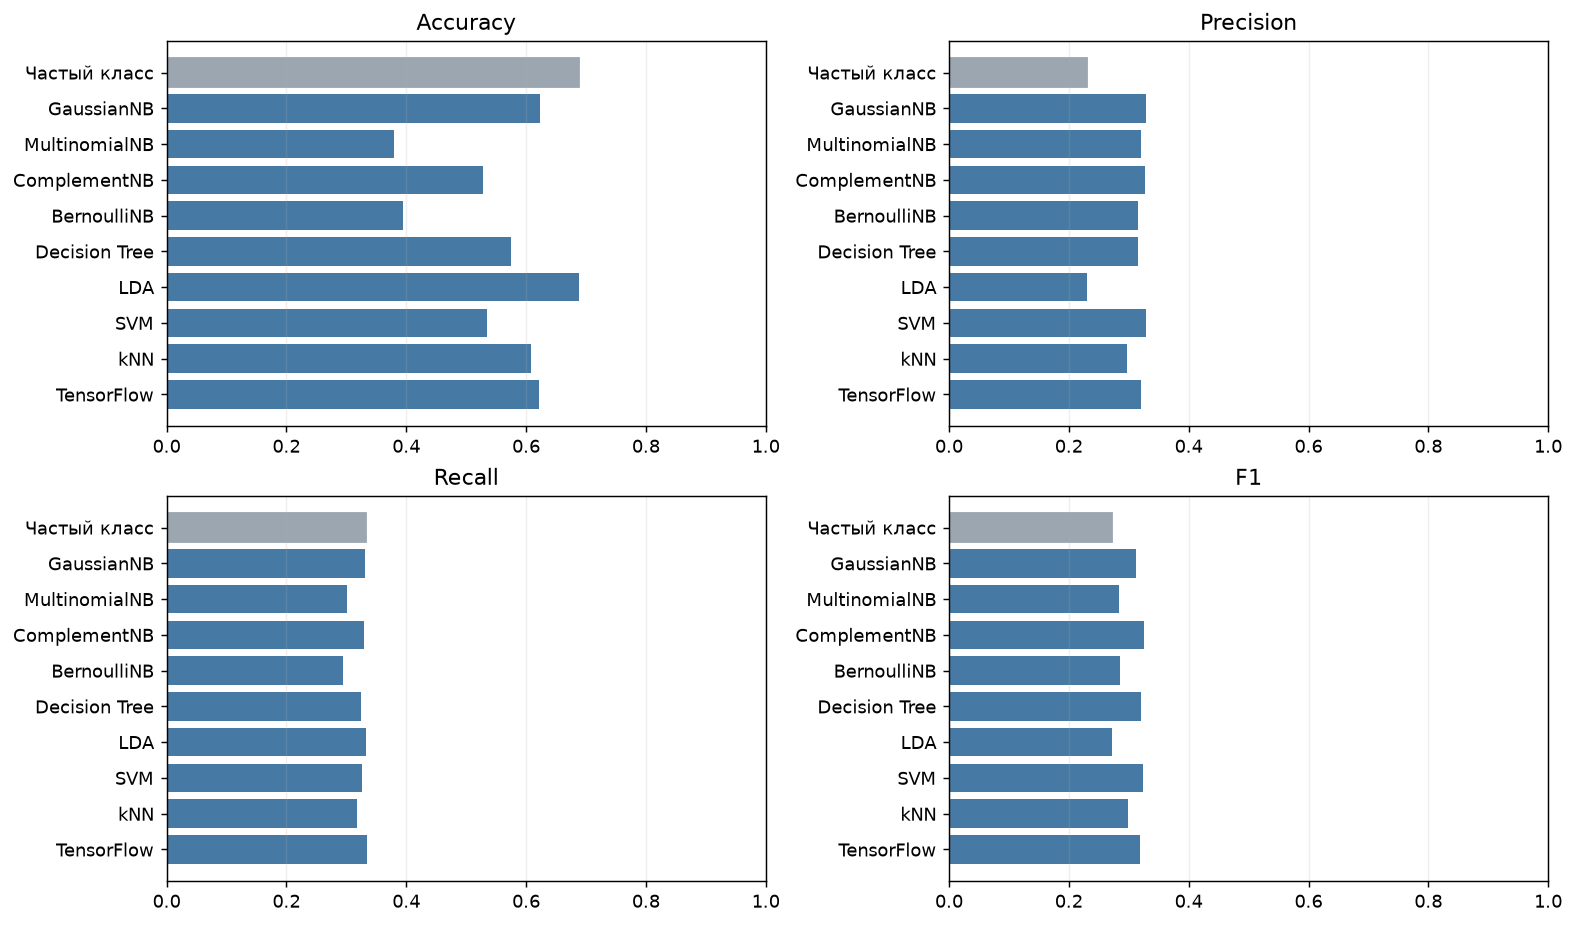

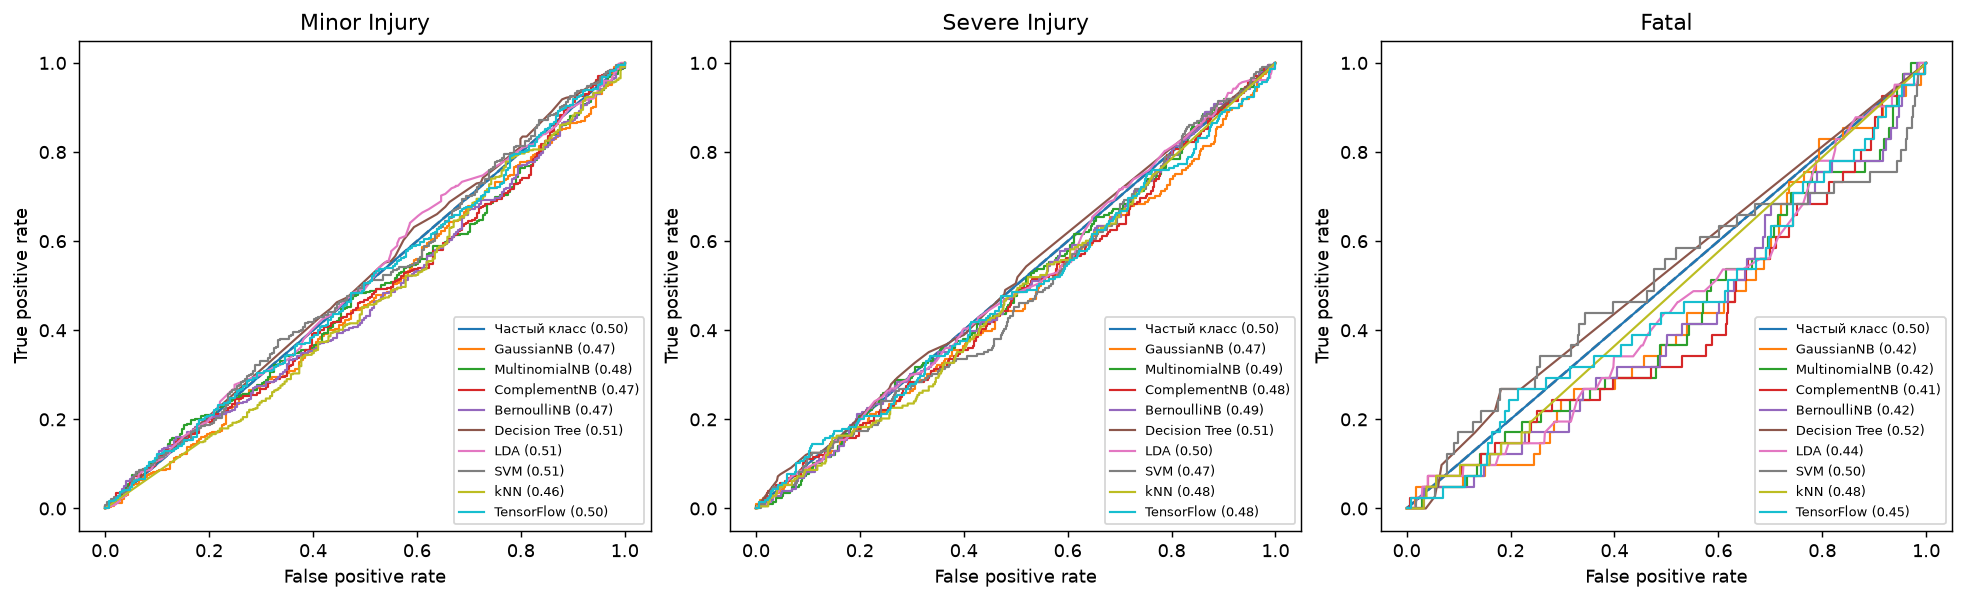

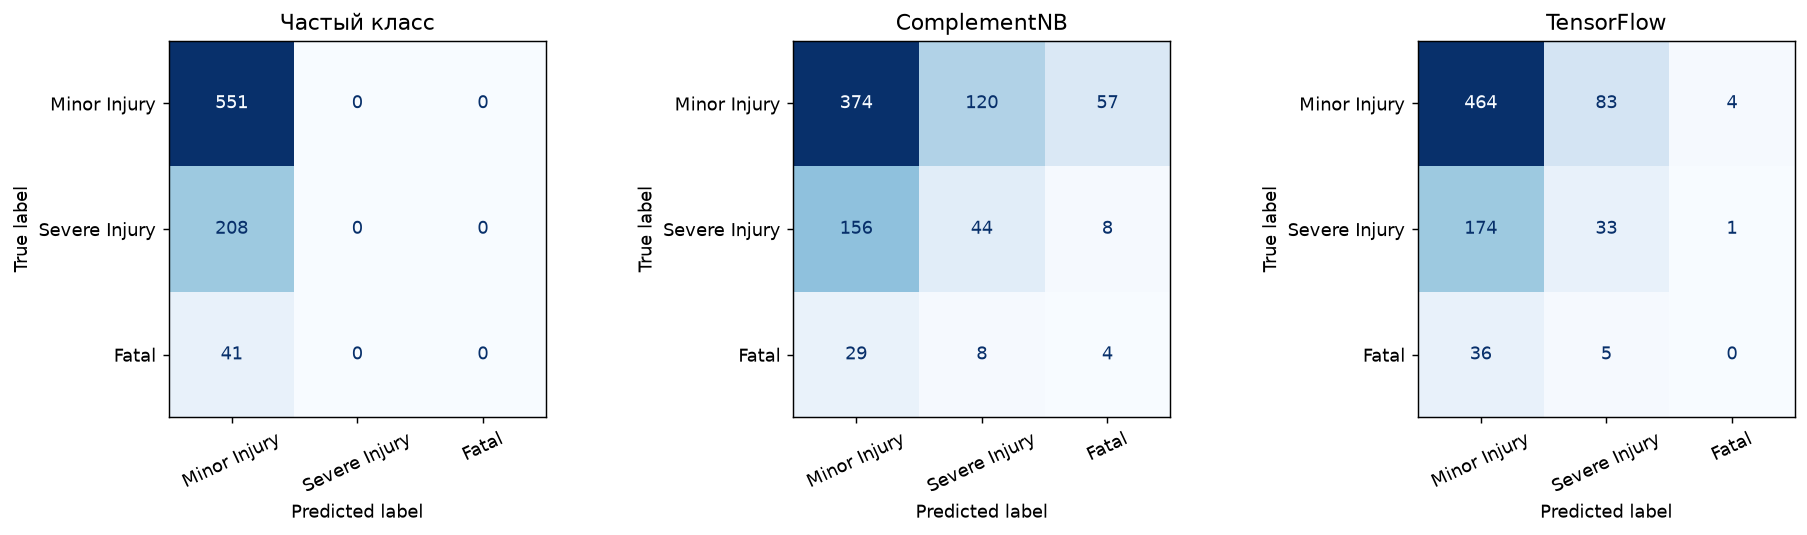

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, metric in zip(axes.flat, ["Accuracy", "Precision", "Recall", "F1"]):
    bars = ax.barh(hold_report.index, hold_report[metric], color="#4679a3")
    bars[0].set_color("#9ca6b0")
    ax.set(xlim=(0, 1), title=metric)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
for i, ax in enumerate(axes):
    ax.plot([0, 1], [0, 1], "--", color="#678")
    for name, curves in hold_curves.items():
        fpr, tpr = curves[i]
        ax.plot(fpr, tpr, linewidth=1.2, label=f"{name} ({auc(fpr,tpr):.2f})")
    ax.set(title=CLASSES[i], xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(fontsize=7, loc="lower right")
plt.show()

show_models = list(dict.fromkeys(["Частый класс", hold_best, "TensorFlow"]))
fig, axes = plt.subplots(1, len(show_models), figsize=(4.8*len(show_models), 4),
                         layout="constrained", squeeze=False)
for ax, name in zip(axes.flat, show_models):
    labels = hold_predictions[name][0]
    cm = confusion_matrix(y_hold, labels, labels=class_ids)
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, colorbar=False, cmap="Blues", xticks_rotation=25
    )
    ax.set_title(name)
plt.show()
fatal_recall = recall_score(y_hold, hold_predictions[hold_best][0], labels=[2],
                           average=None, zero_division=0)[0]
fatal_count = int(y_hold.eq(2).sum())

Столбчатые диаграммы показывают метрики на одной шкале от 0 до 1. ROC-графики разделены по классам, в легенде указаны площади для соответствующего класса. Диагональ служит ориентиром случайного ранжирования. На матрицах ошибок строки — фактические классы, столбцы — предсказанные. У baseline заполнен только столбец `Minor Injury`. У лидера по контрольному макро-F1 полнота класса `Fatal` составляет **9,8%** при 41 фактических случаях. Поэтому даже лучшая общая метрика сама по себе не подтверждает пригодность модели для распознавания редких тяжёлых исходов.

## 8. Заключение

Для сравнения при дисбалансе использован макро-F1. По нему на контрольной выборке лидирует **ComplementNB**, а на отдельном тесте — **Decision Tree**. Максимальный макро-AUC на контроле равен **0,516**. Сеть TensorFlow получила макро-F1 **0,319** на контроле и **0,318** на внешней выборке. Если выбирать классический подход заранее по кросс-валидации, дерево решений показало лучший средний макро-F1 и сохранило первое место на дополнительном тесте. ComplementNB показал лучший макро-F1 на внутреннем контроле. При этом AUC всех моделей близок к 0,5, а простое правило частого класса даёт более высокую Accuracy, чем дерево, ComplementNB или сеть. Ни один из результатов не подтверждает, что модель надёжно определяет тяжесть ДТП, особенно для редкого смертельного исхода.

## Источники

1. Car Crash — три CSV-файла, предоставленные вместе с вариантом задания.
2. [Документация pandas](https://pandas.pydata.org/docs/) и [Matplotlib](https://matplotlib.org/stable/).
3. Scikit-learn. [Наивный Байес](https://scikit-learn.org/stable/modules/naive_bayes.html), [подбор параметров](https://scikit-learn.org/stable/modules/grid_search.html) и [метрики](https://scikit-learn.org/stable/modules/model_evaluation.html).
4. TensorFlow. [Обучение Keras](https://www.tensorflow.org/guide/keras/training_with_built_in_methods) и [TensorBoard](https://www.tensorflow.org/tensorboard/get_started).